# Projet final — Identifier l’utilisateur à partir des traces d’usage

Ce notebook repart des fichiers bruts `data/train.csv` et `data/test.csv`, contrôle leur structure, nettoie et représente les sessions, compare plusieurs familles de modèles, évalue le modèle sélectionné sur des sessions gardées à part, analyse les erreurs puis génère une soumission Kaggle.

**Résultat de l’expérience actuelle :** sur le découpage stratifié externe 80/20, le mélange d’un SVM séquentiel enrichi et d’un Random Forest a obtenu **97,41 % d’accuracy et 0,9726 de F1 macro**. Le mélange a été choisi uniquement sur une validation interne du train. Ce résultat n’atteint pas 98–99 %, n’est pas un score Kaggle et ne garantit pas le classement.

**Important :** `test.csv` n’a pas de colonne utilisateur. Il est impossible de calculer les métriques réelles sur les données Kaggle sans leurs labels. Toutes les métriques du notebook proviennent d’un jeu de validation interne extrait de `train.csv`.


## Plan méthodologique

1. Lire les CSV irréguliers sans en-tête : une ligne par session, longueur variable, label uniquement dans le train.
2. Contrôler les lignes, les champs vides, les utilisateurs, les navigateurs, les durées et les doublons.
3. Créer trois vues séquentielles : événements complets, noms d’action, et contextes d’écran/configuration/chaîne. Garder aussi une vue agrégée pour le Random Forest.
4. Comparer plusieurs classifieurs sur la validation interne, puis isoler un jeu externe stratifié qui ne participe pas à la sélection.
5. Choisir le poids et la température du mélange SVM + Random Forest sur la validation interne; rapporter accuracy, précision, rappel et F1 macro/pondéré sur le holdout externe.
6. Après l’évaluation, réentraîner les modèles sur toutes les lignes étiquetées et sauvegarder `data/processed/final_submission.csv`.

Le SVM linéaire TF-IDF est la composante principale : l’ordre des actions et leurs n-grammes identifient les profils. Les vues d’actions et de contexte complètent les événements exacts. Le Random Forest fournit un signal complémentaire fondé sur des compteurs et statistiques de session.


## 1. Configuration et dépendances

In [1]:
from pathlib import Path
import csv
import hashlib
import re
import sys
import warnings
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import RidgeClassifier, SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

# Configuration principale, pour pouvoir reproduire l'expérience.
SEED = 42
OUTER_VALIDATION_SEED = 31415
INNER_VALIDATION_SEED = 42
OUTER_VALIDATION_SIZE = 0.20
INNER_VALIDATION_SIZE = 0.20
TFIDF_NGRAM_RANGE = (1, 2)
TFIDF_MIN_DF = 2
SVM_C = 5.0
SVM_CLASS_WEIGHT = "balanced"
ACTION_VIEW_WEIGHT = 0.75
CONTEXT_VIEW_WEIGHT = 0.25
RF_TREES = 500
RF_MIN_SAMPLES_LEAF = 2
BLEND_TEMPERATURES = (0.1, 0.2, 0.35, 0.5)
BLEND_RF_WEIGHTS = (0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3)
N_JOBS = -1

warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn")
sns.set_theme(style="whitegrid")
print("Python:", sys.executable, sys.version.split()[0])


Python: /Library/Developer/CommandLineTools/usr/bin/python3 3.9.6


## 2. Chargement et validation des fichiers bruts

On n’utilise pas `pandas.read_csv` pour parser les traces brutes : les lignes n’ont pas toutes le même nombre de champs. Le module `csv` respecte le nombre variable de tokens sans remplir artificiellement les sessions courtes.

In [2]:
def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data" / "train.csv").is_file() and (candidate / "data" / "test.csv").is_file():
            return candidate
    raise FileNotFoundError("Placez/exécutez ce notebook dans le dépôt qui contient data/train.csv et data/test.csv.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / "data"
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

TIME_RE = re.compile(r"^t\d+$")
SCREEN_RE = re.compile(r"\((.*?)\)")
CONFIG_RE = re.compile(r"<(.*?)>")
CHAIN_RE = re.compile(r"\$(.*?)\$")

def read_sessions(path: Path, labeled: bool) -> list[dict]:
    """Read a raw, ragged CSV and preserve original event order."""
    sessions = []
    prefix_size = 2 if labeled else 1
    with path.open(encoding="utf-8", newline="") as stream:
        for row_number, row in enumerate(csv.reader(stream), start=1):
            if len(row) < prefix_size:
                raise ValueError(f"{path.name}, ligne {row_number}: champs d'identité/navigateur manquants")
            row = [field.strip() for field in row]
            if any(field == "" for field in row):
                raise ValueError(f"{path.name}, ligne {row_number}: champ vide détecté")
            if labeled:
                user, browser, events = row[0], row[1], row[2:]
                if not re.fullmatch(r"[a-zA-Z]{3}", user):
                    raise ValueError(f"Identifiant utilisateur inattendu en ligne {row_number}: {user!r}")
            else:
                user, browser, events = None, row[0], row[1:]
            sessions.append({
                "session_id": row_number,
                "util": user,
                "navigateur": browser,
                "events": events,
            })
    return sessions

train_sessions = read_sessions(TRAIN_PATH, labeled=True)
test_sessions = read_sessions(TEST_PATH, labeled=False)
y = np.asarray([session["util"] for session in train_sessions], dtype=str)

sample_path = DATA_DIR / "sample_submission.csv"
sample_submission = pd.read_csv(sample_path)
if sample_submission.columns.tolist() != ["RowId", "prediction"]:
    raise ValueError("L'en-tête du sample_submission.csv n'est pas RowId,prediction")
if len(sample_submission) != len(test_sessions):
    raise ValueError("Le nombre de lignes du sample submission et du test diffère.")

print("Racine:", PROJECT_ROOT)
print(f"Train: {len(train_sessions):,} sessions | Test: {len(test_sessions):,} sessions")
print("Utilisateurs train:", len(set(y)))
print("Champs par session (train) min/max:", min(len(s["events"]) for s in train_sessions), max(len(s["events"]) for s in train_sessions))
print("Champs par session (test) min/max:", min(len(s["events"]) for s in test_sessions), max(len(s["events"]) for s in test_sessions))
print("En-tête submission:", sample_submission.columns.tolist())
display(pd.DataFrame([
    {"session_id": s["session_id"], "util": s["util"], "navigateur": s["navigateur"], "n_events": len(s["events"]), "aperçu": s["events"][:4]}
    for s in train_sessions[:5]
]))

Racine: /Users/macairm1/Desktop/3AECLM2/BE/ML & DS/BE_MachineLearning
Train: 3,279 sessions | Test: 324 sessions
Utilisateurs train: 247
Champs par session (train) min/max: 2 14468
Champs par session (test) min/max: 13 7725
En-tête submission: ['RowId', 'prediction']


,session_id,util,navigateur,n_events,aperçu
0,1,nuh,Firefox,3128,[Création d'un écran(infologic.core.accueil.Ac...
1,2,muz,Google Chrome,136,[Création d'un écran(infologic.core.gui.contro...
2,3,zrx,Microsoft Edge,766,[Affichage d'une dialogue(infologic.core.gui.c...
3,4,pou,Firefox,1199,[Création d'un écran(infologic.core.gui.contro...
4,5,ald,Google Chrome,233,[Affichage d'une dialogue(infologic.acti.modul...


## 3. Exploration et contrôles qualité

Les données contiennent 247 utilisateurs avec des effectifs inégaux. On vérifie la distribution des classes, des navigateurs, des longueurs de session, le vocabulaire des actions et les sessions brutes identiques portant éventuellement des labels différents. Les répétitions de `tNN` ne sont pas des actions et sont exclues de la séquence modèle.

Effectifs utilisateurs min/médiane/max: 4 12 75
Navigateurs train: {'Firefox': 1466, 'Google Chrome': 1339, 'Microsoft Edge': 451, 'Opera': 23}
Navigateurs test: {'Firefox': 147, 'Google Chrome': 133, 'Microsoft Edge': 42, 'Opera': 2}
Actions distinctes: 35 | événements identiques avec labels contradictoires: 0
Marqueurs tNN: valeurs en secondes suivant l'énoncé; ils sont exclus de la séquence d'actions.


,sessions
utilisateur,
skm,75
slq,71
cjr,46
flj,42
hjs,37
vfo,35
shh,34
nqg,34
fwf,33


,sessions,part
navigateur,,
Firefox,1466,0.447
Google Chrome,1339,0.408
Microsoft Edge,451,0.138
Opera,23,0.007


,occurrences
Exécution d'un bouton,510645
Saisie dans un champ,265633
Sélection d'un écran,206813
Fermeture d'une dialogue,171026
Affichage d'une dialogue,168928
Lancement d'une action générique,115283
Sélection d’un onglet,109209
Raccourci,82176
Création d'un écran,76930
Chainage,68194


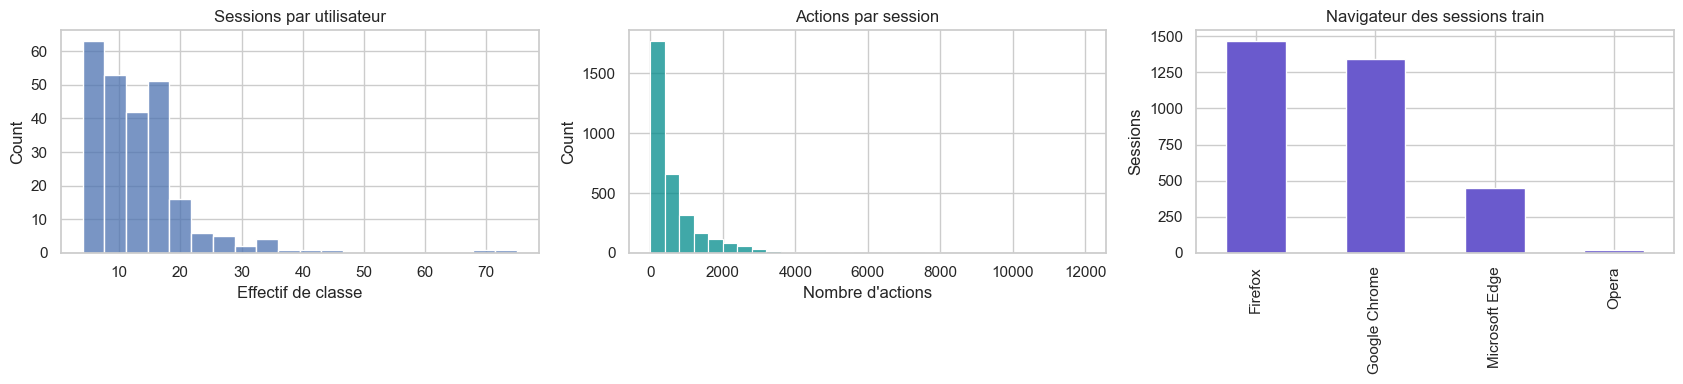

In [3]:
def action_name(event: str) -> str:
    cut_positions = [event.find(mark) for mark in ("(", "<", "$") if event.find(mark) > 0]
    action = event[:min(cut_positions)] if cut_positions else event
    return action[:-1] if action.endswith("1") else action

def session_summary(session: dict) -> dict:
    events = session["events"]
    time_values = [int(token[1:]) for token in events if TIME_RE.fullmatch(token)]
    actions = [action_name(token) for token in events if not TIME_RE.fullmatch(token)]
    screens = [m.group(1) for token in events for m in [SCREEN_RE.search(token)] if m]
    configs = [m.group(1) for token in events for m in [CONFIG_RE.search(token)] if m]
    chains = [m.group(1) for token in events for m in [CHAIN_RE.search(token)] if m]
    return {
        "session_id": session["session_id"],
        "util": session["util"],
        "navigateur": session["navigateur"],
        "n_tokens": len(events),
        "n_actions": len(actions),
        "n_time_markers": len(time_values),
        "max_time_seconds": max(time_values, default=0),
        "n_distinct_actions": len(set(actions)),
        "n_screens": len(screens),
        "n_distinct_screens": len(set(screens)),
        "n_configs": len(configs),
        "n_chains": len(chains),
    }

train_meta = pd.DataFrame([session_summary(s) for s in train_sessions])
test_meta = pd.DataFrame([session_summary(s) for s in test_sessions])
class_counts = train_meta["util"].value_counts()
browser_counts = train_meta["navigateur"].value_counts()
all_actions = Counter(action_name(token) for s in train_sessions for token in s["events"] if not TIME_RE.fullmatch(token))

def sequence_signature(session: dict) -> str:
    canonical = "\x1e".join([session["navigateur"], *[t for t in session["events"] if not TIME_RE.fullmatch(t)]])
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()

duplicate_labels = defaultdict(set)
for session in train_sessions:
    duplicate_labels[sequence_signature(session)].add(session["util"])
exact_duplicate_groups = [labels for labels in duplicate_labels.values() if len(labels) > 1]

print("Effectifs utilisateurs min/médiane/max:", int(class_counts.min()), int(class_counts.median()), int(class_counts.max()))
print("Navigateurs train:", browser_counts.to_dict())
print("Navigateurs test:", test_meta["navigateur"].value_counts().to_dict())
print("Actions distinctes:", len(all_actions), "| événements identiques avec labels contradictoires:", len(exact_duplicate_groups))
print("Marqueurs tNN: valeurs en secondes suivant l'énoncé; ils sont exclus de la séquence d'actions.")
display(class_counts.head(15).rename_axis("utilisateur").to_frame("sessions"))
display(pd.DataFrame({"sessions": browser_counts, "part": (browser_counts / len(train_meta)).round(3)}))
display(pd.Series(all_actions).sort_values(ascending=False).head(15).rename("occurrences").to_frame())

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(class_counts, bins=20, ax=axes[0])
axes[0].set(title="Sessions par utilisateur", xlabel="Effectif de classe")
sns.histplot(train_meta["n_actions"], bins=30, ax=axes[1], color="darkcyan")
axes[1].set(title="Actions par session", xlabel="Nombre d'actions")
browser_counts.plot(kind="bar", ax=axes[2], color="slateblue")
axes[2].set(title="Navigateur des sessions train", ylabel="Sessions", xlabel="")
plt.tight_layout()
plt.show()

## 4. Construire les vues séquentielles et les caractéristiques

**SVM — séquences TF-IDF complémentaires.** Une première vue conserve chaque événement complet et son ordre. Deux autres vues extraient les noms d’action et les contextes d’écran, configuration et chaîne. Les vues sont vectorisées séparément (n-grammes d’événements et d’actions, contextes unigrammes), puis concaténées avec des poids fixés. Le navigateur est présent dans chaque vue. Les marqueurs `tNN` sont exclus des séquences.

**Random Forest — caractéristiques interprétables.** Pour chaque session, compter les types d’action, événements complets et contextes extraits (`(...)`, `<...>`, `$...$`), avec des résumés numériques et le navigateur. Un `DictVectorizer` apprend l’encodage sur le sous-ensemble d’entraînement uniquement.

La cible `util` n’entre dans aucune vue de caractéristiques.


In [4]:
TOKEN_SEPARATOR = "\x1f"

def sequence_document(session: dict, include_time_markers: bool = False) -> str:
    tokens = [f"BROWSER={session['navigateur']}"]
    tokens.extend(
        token for token in session["events"]
        if include_time_markers or not TIME_RE.fullmatch(token)
    )
    return TOKEN_SEPARATOR.join(tokens)

def semantic_documents(session: dict) -> tuple[str, str]:
    actions = [f"BROWSER={session['navigateur']}"]
    contexts = [f"BROWSER={session['navigateur']}"]
    for event in session["events"]:
        if TIME_RE.fullmatch(event):
            continue
        actions.append(f"ACTION={action_name(event)}")
        for prefix, pattern in (("SCREEN", SCREEN_RE), ("CONFIG", CONFIG_RE), ("CHAIN", CHAIN_RE)):
            match = pattern.search(event)
            if match:
                contexts.append(f"{prefix}={match.group(1)}")
    return TOKEN_SEPARATOR.join(actions), TOKEN_SEPARATOR.join(contexts)

def rf_features(session: dict) -> dict[str, float]:
    events = session["events"]
    counts = Counter()
    times = []
    actions = []
    screens = []
    configs = []
    chains = []
    modified = 0

    for token in events:
        if TIME_RE.fullmatch(token):
            times.append(int(token[1:]))
            continue
        action = action_name(token)
        actions.append(action)
        counts[f"action__{action}"] += 1
        counts[f"event__{token}"] += 1
        modified += token.endswith("1")
        for prefix, pattern, destination in (
            ("screen", SCREEN_RE, screens),
            ("config", CONFIG_RE, configs),
            ("chain", CHAIN_RE, chains),
        ):
            match = pattern.search(token)
            if match:
                value = match.group(1)
                destination.append(value)
                counts[f"{prefix}__{value}"] += 1

    counts.update({
        f"browser__{session['navigateur']}": 1,
        "summary__n_tokens": len(events),
        "summary__n_actions": len(actions),
        "summary__n_time_markers": len(times),
        "summary__max_time_seconds": max(times, default=0),
        "summary__n_distinct_actions": len(set(actions)),
        "summary__n_screens": len(screens),
        "summary__n_distinct_screens": len(set(screens)),
        "summary__n_configs": len(configs),
        "summary__n_distinct_configs": len(set(configs)),
        "summary__n_chains": len(chains),
        "summary__n_distinct_chains": len(set(chains)),
        "summary__n_modified_actions": modified,
    })
    return dict(counts)

train_documents = [sequence_document(s) for s in train_sessions]
test_documents = [sequence_document(s) for s in test_sessions]
train_action_documents, train_context_documents = zip(*(semantic_documents(s) for s in train_sessions))
test_action_documents, test_context_documents = zip(*(semantic_documents(s) for s in test_sessions))
train_rf_rows = [rf_features(s) for s in train_sessions]
test_rf_rows = [rf_features(s) for s in test_sessions]

print("SVM: document examples, tokens are separated with an internal delimiter:")
display(pd.DataFrame({"util": y[:3], "ordered_tokens": [s.split(TOKEN_SEPARATOR)[:8] for s in train_documents[:3]]}))
print("RF: number of distinct numeric/categorical keys in first rows:", [len(row) for row in train_rf_rows[:5]])
print("Unique action types:", len(all_actions))


SVM: document examples, tokens are separated with an internal delimiter:


,util,ordered_tokens
0,nuh,"[BROWSER=Firefox, Création d'un écran(infologi..."
1,muz,"[BROWSER=Google Chrome, Création d'un écran(in..."
2,zrx,"[BROWSER=Microsoft Edge, Affichage d'une dialo..."


RF: number of distinct numeric/categorical keys in first rows: [97, 56, 144, 103, 78]
Unique action types: 35


## 5. Validation imbriquée — séparation anti-fuite

Le split externe est mis de côté pour l’évaluation finale. Le poids du mélange et sa température sont choisis exclusivement sur le split interne du train externe. Aucun vocabulaire TF-IDF, encodage Random Forest, poids de mélange, ni autre prétraitement n’est ajusté avec les lignes externes d’évaluation.

La stratification est nécessaire pour garder des exemples de chaque utilisateur dans les ensembles. Les classes les plus rares ont quatre sessions seulement; leurs métriques par utilisateur sont nécessairement plus incertaines.

In [5]:
indices = np.arange(len(y))
dev_idx, outer_eval_idx = train_test_split(
    indices,
    test_size=OUTER_VALIDATION_SIZE,
    random_state=OUTER_VALIDATION_SEED,
    stratify=y,
)
inner_fit_idx, inner_val_idx = train_test_split(
    dev_idx,
    test_size=INNER_VALIDATION_SIZE,
    random_state=INNER_VALIDATION_SEED,
    stratify=y[dev_idx],
)

split_table = pd.DataFrame([
    {"split": "fit interne", "sessions": len(inner_fit_idx), "utilisateurs présents": len(set(y[inner_fit_idx]))},
    {"split": "validation de sélection", "sessions": len(inner_val_idx), "utilisateurs présents": len(set(y[inner_val_idx]))},
    {"split": "validation externe finale", "sessions": len(outer_eval_idx), "utilisateurs présents": len(set(y[outer_eval_idx]))},
])
display(split_table)
assert set(y[inner_fit_idx]) == set(y[dev_idx])
assert set(y[outer_eval_idx]).issubset(set(y[dev_idx]))
assert not (set(outer_eval_idx) & set(dev_idx))

,split,sessions,utilisateurs présents
0,fit interne,2098,247
1,validation de sélection,525,247
2,validation externe finale,656,247


## 6. Comparaison des algorithmes et réglage du mélange

La comparaison interne teste des classifieurs différents sur la vue TF-IDF des événements : SVM linéaire, Ridge, SGD à perte logistique, Complement Naive Bayes et k plus proches voisins. La sélection finale ajoute des vues explicites d’actions et de contextes au SVM, car les essais montrent que ces informations apportent des indices complémentaires.

Le SVM retenu utilise des n-grammes (1 à 2), `min_df=2`, `C=5` et des poids de classes équilibrés. Le Random Forest utilise des compteurs/contextes, 500 arbres, `max_features='sqrt'`, feuilles de taille minimale 2 et `balanced_subsample`.

Les marges SVM sont converties en scores par softmax; température et poids RF sont choisis par F1 macro sur la validation interne, puis verrouillés avant l’évaluation externe.


In [6]:
def build_tfidf(ngram_range=TFIDF_NGRAM_RANGE, min_df=TFIDF_MIN_DF) -> TfidfVectorizer:
    return TfidfVectorizer(
        tokenizer=lambda document: document.split(TOKEN_SEPARATOR),
        preprocessor=None,
        token_pattern=None,
        lowercase=False,
        ngram_range=ngram_range,
        min_df=min_df,
        sublinear_tf=True,
        dtype=np.float32,
    )

def build_svm() -> LinearSVC:
    return LinearSVC(C=SVM_C, class_weight=SVM_CLASS_WEIGHT, random_state=SEED, dual="auto")

def build_rf() -> RandomForestClassifier:
    return RandomForestClassifier(
        n_estimators=RF_TREES,
        max_features="sqrt",
        min_samples_leaf=RF_MIN_SAMPLES_LEAF,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=N_JOBS,
    )

def vectorize_svm_views(fit_views, predict_views):
    specifications = (
        ("événements", TFIDF_NGRAM_RANGE, TFIDF_MIN_DF, 1.0),
        ("actions", TFIDF_NGRAM_RANGE, TFIDF_MIN_DF, ACTION_VIEW_WEIGHT),
        ("contextes", (1, 1), TFIDF_MIN_DF, CONTEXT_VIEW_WEIGHT),
    )
    fit_blocks = []
    predict_blocks = []
    vectorizers = {}
    for (name, ngram_range, min_df, weight), fit_texts, predict_texts in zip(
        specifications, fit_views, predict_views
    ):
        vectorizer = build_tfidf(ngram_range=ngram_range, min_df=min_df)
        fit_blocks.append(weight * vectorizer.fit_transform(fit_texts))
        predict_blocks.append(weight * vectorizer.transform(predict_texts))
        vectorizers[name] = vectorizer
    from scipy.sparse import hstack
    return hstack(fit_blocks, format="csr"), hstack(predict_blocks, format="csr"), vectorizers

def svm_views(indices):
    return (
        [train_documents[i] for i in indices],
        [train_action_documents[i] for i in indices],
        [train_context_documents[i] for i in indices],
    )

def fit_pair(fit_indices: np.ndarray, predict_indices: np.ndarray, seed: int):
    """Fit complementary text and count models using only fit_indices."""
    X_svm_fit, X_svm_predict, vectorizers = vectorize_svm_views(
        svm_views(fit_indices), svm_views(predict_indices)
    )
    svm = build_svm().set_params(random_state=seed)
    svm.fit(X_svm_fit, y[fit_indices])
    svm_margins = svm.decision_function(X_svm_predict)

    dict_vectorizer = DictVectorizer(sparse=True, dtype=np.float32)
    X_rf_fit = dict_vectorizer.fit_transform([train_rf_rows[i] for i in fit_indices])
    X_rf_predict = dict_vectorizer.transform([train_rf_rows[i] for i in predict_indices])
    rf = build_rf().set_params(random_state=seed)
    rf.fit(X_rf_fit, y[fit_indices])
    rf_probabilities_raw = rf.predict_proba(X_rf_predict)

    svm_classes = svm.classes_
    rf_column = {label: column for column, label in enumerate(rf.classes_)}
    rf_probabilities = np.zeros((len(predict_indices), len(svm_classes)), dtype=np.float64)
    for column, label in enumerate(svm_classes):
        if label in rf_column:
            rf_probabilities[:, column] = rf_probabilities_raw[:, rf_column[label]]
    return {
        "classes": svm_classes,
        "svm_margins": svm_margins,
        "rf_probabilities": rf_probabilities,
        "svm": svm,
        "rf": rf,
        "svm_vectorizers": vectorizers,
        "svm_fit_matrix": X_svm_fit,
        "dict_vectorizer": dict_vectorizer,
    }

def svm_probabilities(margins: np.ndarray, temperature: float) -> np.ndarray:
    scaled = margins / temperature
    scaled = scaled - scaled.max(axis=1, keepdims=True)
    exp_scores = np.exp(scaled)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)

def blended_prediction(model_outputs: dict, temperature: float, rf_weight: float) -> np.ndarray:
    svm_probs = svm_probabilities(model_outputs["svm_margins"], temperature)
    combined = (1.0 - rf_weight) * svm_probs + rf_weight * model_outputs["rf_probabilities"]
    return model_outputs["classes"][combined.argmax(axis=1)]

def metrics_row(name: str, truth: np.ndarray, prediction: np.ndarray) -> dict:
    p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(truth, prediction, average="macro", zero_division=0)
    p_weighted, r_weighted, f_weighted, _ = precision_recall_fscore_support(truth, prediction, average="weighted", zero_division=0)
    return {
        "Modèle": name,
        "Accuracy": accuracy_score(truth, prediction),
        "Précision macro": p_macro,
        "Rappel macro": r_macro,
        "F1 macro": f_macro,
        "Précision pondérée": p_weighted,
        "Rappel pondéré": r_weighted,
        "F1 pondéré": f_weighted,
    }

event_vectorizer = build_tfidf(ngram_range=(1, 3), min_df=2)
X_event_fit = event_vectorizer.fit_transform([train_documents[i] for i in inner_fit_idx])
X_event_val = event_vectorizer.transform([train_documents[i] for i in inner_val_idx])
inner_truth = y[inner_val_idx]
benchmark_models = [
    ("SVM linéaire — événements", LinearSVC(C=3, class_weight="balanced", dual="auto", random_state=SEED)),
    ("Ridge", RidgeClassifier(alpha=1, class_weight="balanced")),
    ("SGD log_loss", SGDClassifier(loss="log_loss", alpha=1e-5, class_weight="balanced", max_iter=1000, tol=1e-4, random_state=SEED, n_jobs=N_JOBS)),
    ("Complement Naive Bayes", ComplementNB(alpha=0.1)),
    ("1-NN cosinus", KNeighborsClassifier(n_neighbors=1, metric="cosine", algorithm="brute", n_jobs=N_JOBS)),
]
benchmark_rows = []
for model_name, model in benchmark_models:
    model.fit(X_event_fit, y[inner_fit_idx])
    benchmark_rows.append(metrics_row(model_name, inner_truth, model.predict(X_event_val)))
print("Comparaison exploratoire sur la même validation interne (représentation TF-IDF des événements):")
display(pd.DataFrame(benchmark_rows).sort_values(["F1 macro", "Accuracy"], ascending=False).round(4))

inner_models = fit_pair(inner_fit_idx, inner_val_idx, SEED)
inner_svm_pred = inner_models["classes"][inner_models["svm_margins"].argmax(axis=1)]
inner_rf_pred = inner_models["classes"][inner_models["rf_probabilities"].argmax(axis=1)]
inner_base_metrics = pd.DataFrame([
    metrics_row("SVM événements + actions + contextes", inner_truth, inner_svm_pred),
    metrics_row("Random Forest", inner_truth, inner_rf_pred),
])
print("Modèles retenus pour l'ensemble:")
display(inner_base_metrics.round(4))

blend_trials = []
for temperature in BLEND_TEMPERATURES:
    for rf_weight in BLEND_RF_WEIGHTS:
        prediction = blended_prediction(inner_models, temperature, rf_weight)
        row = metrics_row("mélange", inner_truth, prediction)
        row.update({"température": temperature, "poids_RF": rf_weight})
        blend_trials.append(row)
blend_trials_df = pd.DataFrame(blend_trials).sort_values(["F1 macro", "Accuracy"], ascending=False)
display(blend_trials_df.head(10).round(4))
best_blend = blend_trials_df.iloc[0]
BEST_TEMPERATURE = float(best_blend["température"])
BEST_RF_WEIGHT = float(best_blend["poids_RF"])
print(f"Paramètres du mélange choisis sur validation interne uniquement: température={BEST_TEMPERATURE}, poids RF={BEST_RF_WEIGHT}")


Comparaison exploratoire sur la même validation interne (représentation TF-IDF des événements):


,Modèle,Accuracy,Précision macro,Rappel macro,F1 macro,Précision pondérée,Rappel pondéré,F1 pondéré
0,SVM linéaire — événements,0.9390,0.9305,0.9348,0.9265,0.9381,0.9390,0.9319
1,Ridge,0.9295,0.9227,0.9293,0.9183,0.9312,0.9295,0.9223
2,SGD log_loss,0.9295,0.9207,0.9240,0.9146,0.9283,0.9295,0.9204
4,1-NN cosinus,0.8838,0.8674,0.8771,0.8607,0.8852,0.8838,0.8728
3,Complement Naive Bayes,0.8438,0.7613,0.7867,0.7600,0.8074,0.8438,0.8101


Modèles retenus pour l'ensemble:


,Modèle,Accuracy,Précision macro,Rappel macro,F1 macro,Précision pondérée,Rappel pondéré,F1 pondéré
0,SVM événements + actions + contextes,0.9543,0.9468,0.9486,0.9447,0.9510,0.9543,0.9490
1,Random Forest,0.8933,0.8659,0.8718,0.8582,0.8884,0.8933,0.8792


,Modèle,Accuracy,Précision macro,Rappel macro,F1 macro,Précision pondérée,Rappel pondéré,F1 pondéré,température,poids_RF
22,mélange,0.9581,0.9607,0.9594,0.9572,0.9580,0.9581,0.9545,0.50,0.05
17,mélange,0.9562,0.9603,0.9590,0.9568,0.9565,0.9562,0.9528,0.35,0.15
23,mélange,0.9562,0.9569,0.9570,0.9539,0.9553,0.9562,0.9520,0.50,0.10
11,mélange,0.9562,0.9558,0.9553,0.9527,0.9546,0.9562,0.9517,0.20,0.20
12,mélange,0.9562,0.9558,0.9553,0.9527,0.9546,0.9562,0.9517,0.20,0.25
13,mélange,0.9562,0.9558,0.9553,0.9527,0.9546,0.9562,0.9517,0.20,0.30
16,mélange,0.9562,0.9558,0.9553,0.9527,0.9546,0.9562,0.9517,0.35,0.10
15,mélange,0.9524,0.9504,0.9492,0.9470,0.9514,0.9524,0.9483,0.35,0.05
18,mélange,0.9524,0.9488,0.9509,0.9465,0.9505,0.9524,0.9475,0.35,0.20
10,mélange,0.9524,0.9500,0.9482,0.9459,0.9515,0.9524,0.9480,0.20,0.15


Paramètres du mélange choisis sur validation interne uniquement: température=0.5, poids RF=0.05


## 7. Évaluation externe verrouillée

Les réglages de mélange sont maintenant fixés. Les deux modèles sont entraînés sur le développement complet (80 % du train); aucune décision de modèle n’est prise à partir des résultats externes ci-dessous. On compare la baseline majoritaire, le SVM enrichi, le Random Forest et leur mélange.


In [7]:
outer_models = fit_pair(dev_idx, outer_eval_idx, SEED)
outer_truth = y[outer_eval_idx]
outer_svm_pred = outer_models["classes"][outer_models["svm_margins"].argmax(axis=1)]
outer_rf_pred = outer_models["classes"][outer_models["rf_probabilities"].argmax(axis=1)]
outer_blend_pred = blended_prediction(outer_models, BEST_TEMPERATURE, BEST_RF_WEIGHT)
majority_label = Counter(y[dev_idx]).most_common(1)[0][0]
majority_pred = np.repeat(majority_label, len(outer_eval_idx))

outer_metrics = pd.DataFrame([
    metrics_row("Baseline — classe majoritaire", outer_truth, majority_pred),
    metrics_row("SVM événements + actions + contextes", outer_truth, outer_svm_pred),
    metrics_row("Random Forest sur compteurs", outer_truth, outer_rf_pred),
    metrics_row("Mélange SVM + Random Forest", outer_truth, outer_blend_pred),
]).sort_values("F1 macro", ascending=False).reset_index(drop=True)
display(outer_metrics.round(4))
print("Taille de l'évaluation externe:", len(outer_eval_idx), "sessions")
print("Les métriques sont calculées sur validation interne, non sur le test Kaggle.")

outer_train_svm_pred = outer_models["svm"].predict(outer_models["svm_fit_matrix"])
outer_train_rf_pred = outer_models["rf"].predict(outer_models["dict_vectorizer"].transform([train_rf_rows[i] for i in dev_idx]))
generalization_gap = pd.DataFrame([
    metrics_row("SVM enrichi — train de fit", y[dev_idx], outer_train_svm_pred),
    metrics_row("SVM enrichi — validation externe", outer_truth, outer_svm_pred),
    metrics_row("RF — train de fit", y[dev_idx], outer_train_rf_pred),
    metrics_row("RF — validation externe", outer_truth, outer_rf_pred),
])
print("Comparaison train / validation pour détecter la mémorisation:")
display(generalization_gap[["Modèle", "Accuracy", "F1 macro", "F1 pondéré"]].round(4))


,Modèle,Accuracy,Précision macro,Rappel macro,F1 macro,Précision pondérée,Rappel pondéré,F1 pondéré
0,Mélange SVM + Random Forest,0.9741,0.9775,0.9730,0.9726,0.9752,0.9741,0.9716
1,SVM événements + actions + contextes,0.9680,0.9705,0.9663,0.9654,0.9687,0.9680,0.9648
2,Random Forest sur compteurs,0.8872,0.8685,0.8718,0.8584,0.8881,0.8872,0.8752
3,Baseline — classe majoritaire,0.0229,0.0001,0.0040,0.0002,0.0005,0.0229,0.0010


Taille de l'évaluation externe: 656 sessions
Les métriques sont calculées sur validation interne, non sur le test Kaggle.
Comparaison train / validation pour détecter la mémorisation:


,Modèle,Accuracy,F1 macro,F1 pondéré
0,SVM enrichi — train de fit,1.0000,1.0000,1.0000
1,SVM enrichi — validation externe,0.9680,0.9654,0.9648
2,RF — train de fit,0.9977,0.9988,0.9977
3,RF — validation externe,0.8872,0.8584,0.8752


## 8. Analyse des erreurs et variables Random Forest

Le F1 macro est la moyenne par utilisateur et rend visibles les classes rares. Les scores par classe ayant quatre sessions sont toutefois très sensibles au split. L’importance Random Forest est un indicateur interne aux arbres, non une relation causale.

15 classes les moins représentées dans l'évaluation externe:


,precision,recall,f1-score,support
utilisateur,,,,
azn,0.0,0.0,0.0,1.0
jew,0.0,0.0,0.0,1.0
ufc,0.0,0.0,0.0,1.0
bez,1.0,1.0,1.0,1.0
cka,1.0,1.0,1.0,1.0
ckl,1.0,1.0,1.0,1.0
crn,1.0,1.0,1.0,1.0
cum,1.0,1.0,1.0,1.0
cuw,1.0,1.0,1.0,1.0


Erreurs du mélange: 17 / 656 (2.6%)


,session_id,utilisateur_reel,utilisateur_predit,n_actions,navigateur
0,299,bos,czi,128,Firefox
28,1574,vek,jew,161,Firefox
31,2613,slq,skm,51,Google Chrome
110,619,ald,fuy,65,Google Chrome
148,298,azn,wht,87,Google Chrome
162,290,kks,tdk,35,Firefox
224,925,yvq,muz,130,Google Chrome
226,1306,guh,sps,122,Google Chrome
232,2489,flj,skm,47,Google Chrome
241,1571,jew,flj,115,Firefox


,caractéristique,importance_Gini
8,action__Clic sur une grille d'historique de re...,0.007108
1594,event__Clic sur une grille d'historique de rec...,0.006912
35,browser__Firefox,0.006491
3840,event__Raccourci,0.006457
36,browser__Google Chrome,0.006289
363,event__Affichage d'un toast,0.006259
4205,event__Retour sur un écran,0.006110
3650,event__Filtrage / Tri,0.006092
27,action__Raccourci,0.005994
21,action__Filtrage / Tri,0.005950


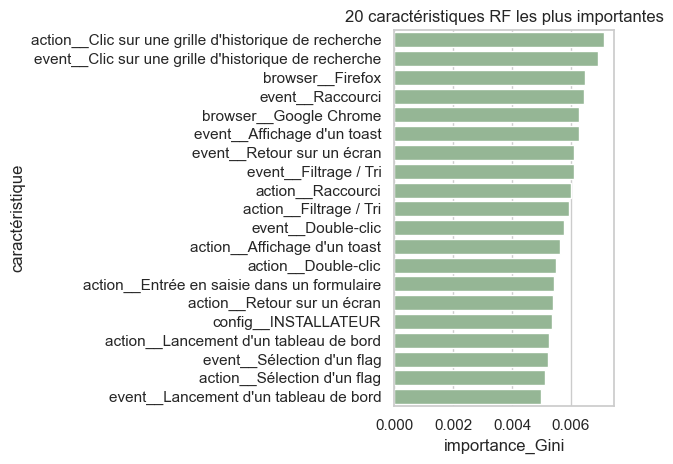

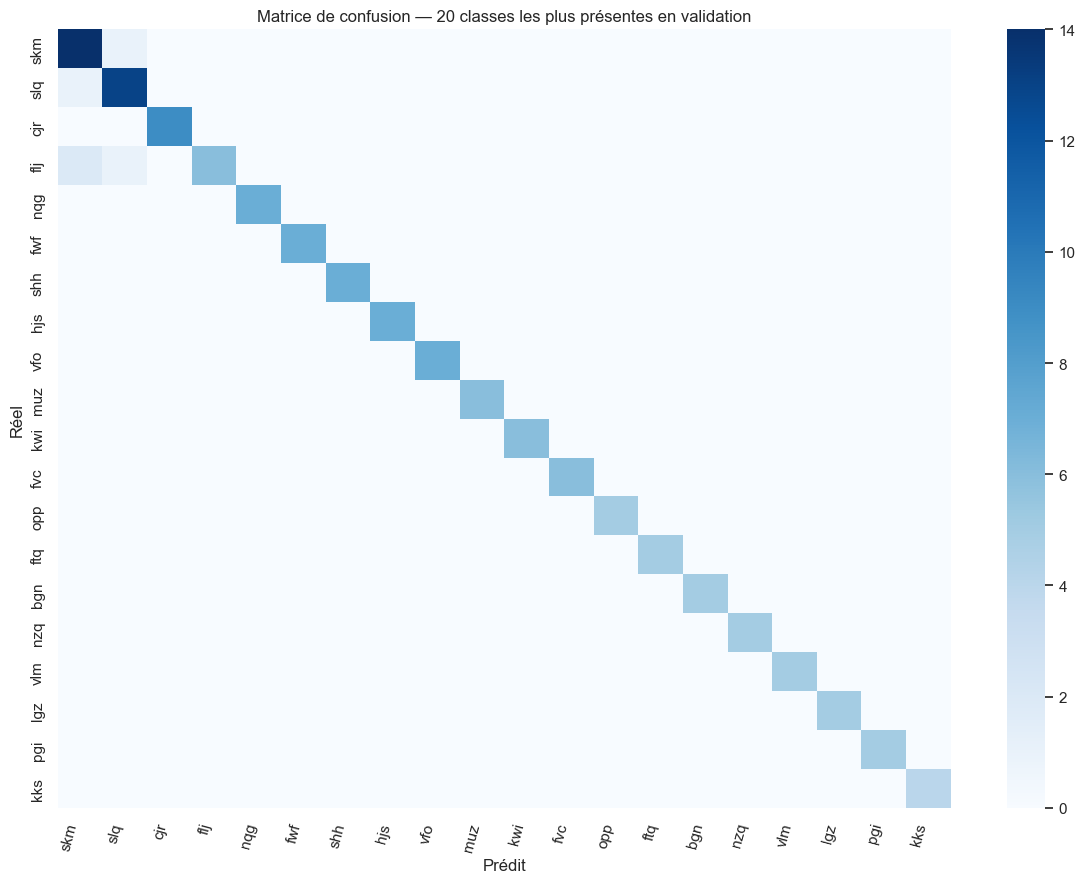

In [8]:
per_user = pd.DataFrame(classification_report(
    outer_truth,
    outer_blend_pred,
    labels=outer_models["classes"],
    output_dict=True,
    zero_division=0,
)).T
per_user = per_user.loc[per_user.index.isin(outer_models["classes"].astype(str))].copy()
per_user.index.name = "utilisateur"
per_user = per_user.sort_values(["support", "f1-score"], ascending=[True, True])
print("15 classes les moins représentées dans l'évaluation externe:")
display(per_user.head(15).round(3))

errors = pd.DataFrame({
    "session_id": [train_sessions[i]["session_id"] for i in outer_eval_idx],
    "utilisateur_reel": outer_truth,
    "utilisateur_predit": outer_blend_pred,
    "n_actions": [train_meta.iloc[i]["n_actions"] for i in outer_eval_idx],
    "navigateur": [train_sessions[i]["navigateur"] for i in outer_eval_idx],
})
errors = errors[errors["utilisateur_reel"] != errors["utilisateur_predit"]]
print(f"Erreurs du mélange: {len(errors)} / {len(outer_eval_idx)} ({len(errors)/len(outer_eval_idx):.1%})")
display(errors.head(20))

rf_vectorizer_outer = outer_models["dict_vectorizer"]
rf_importance = pd.DataFrame({
    "caractéristique": rf_vectorizer_outer.get_feature_names_out(),
    "importance_Gini": outer_models["rf"].feature_importances_,
}).sort_values("importance_Gini", ascending=False)
display(rf_importance.head(25))
sns.barplot(data=rf_importance.head(20), x="importance_Gini", y="caractéristique", color="darkseagreen")
plt.title("20 caractéristiques RF les plus importantes")
plt.tight_layout()
plt.show()

top_eval_classes = pd.Series(outer_truth).value_counts().head(20).index.to_list()
cm = confusion_matrix(outer_truth, outer_blend_pred, labels=top_eval_classes)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, cmap="Blues", xticklabels=top_eval_classes, yticklabels=top_eval_classes)
plt.title("Matrice de confusion — 20 classes les plus présentes en validation")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 9. Réentraînement sur tout le train et prédiction Kaggle

Après l’évaluation, les modèles sont réentraînés sur toutes les sessions étiquetées. Le vocabulaire TF-IDF et le DictVectorizer sont refaits sur le train complet. Les prédictions test sont converties dans les identifiants utilisateur d’origine et sauvegardées dans l’ordre du fichier test.

In [9]:
all_train_views = (train_documents, train_action_documents, train_context_documents)
test_views = (test_documents, test_action_documents, test_context_documents)
X_train_seq, X_test_seq, final_svm_vectorizers = vectorize_svm_views(all_train_views, test_views)
final_svm = build_svm()
final_svm.fit(X_train_seq, y)
test_svm_margins = final_svm.decision_function(X_test_seq)

final_dict_vectorizer = DictVectorizer(sparse=True, dtype=np.float32)
X_train_counts = final_dict_vectorizer.fit_transform(train_rf_rows)
X_test_counts = final_dict_vectorizer.transform(test_rf_rows)
final_rf = build_rf()
final_rf.fit(X_train_counts, y)
test_rf_raw = final_rf.predict_proba(X_test_counts)

test_rf_probabilities = np.zeros((len(test_sessions), len(final_svm.classes_)), dtype=np.float64)
rf_label_to_column = {label: column for column, label in enumerate(final_rf.classes_)}
for column, label in enumerate(final_svm.classes_):
    test_rf_probabilities[:, column] = test_rf_raw[:, rf_label_to_column[label]]
final_outputs = {
    "classes": final_svm.classes_,
    "svm_margins": test_svm_margins,
    "rf_probabilities": test_rf_probabilities,
}
test_predictions = blended_prediction(final_outputs, BEST_TEMPERATURE, BEST_RF_WEIGHT)

submission = pd.DataFrame({
    "RowId": np.arange(1, len(test_predictions) + 1),
    "prediction": test_predictions,
})
submission_path = DATA_DIR / "processed" / "final_submission.csv"
submission_path.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(submission_path, index=False)

assert submission.columns.tolist() == ["RowId", "prediction"]
assert len(submission) == len(test_sessions) == len(sample_submission)
assert submission["RowId"].tolist() == sample_submission["RowId"].tolist()

print("Vocabulaire TF-IDF par vue:", {name: len(vectorizer.vocabulary_) for name, vectorizer in final_svm_vectorizers.items()})
print("Variables Random Forest:", X_train_counts.shape[1])
print("Prédictions:", len(submission), "| utilisateurs prédits:", submission["prediction"].nunique())
print("Fichier prêt pour Kaggle:", submission_path)
display(submission.head(10))
display(submission["prediction"].value_counts().head(15).rename("prédictions").to_frame())
print("Aucun score test n'est calculé : les labels utilisateurs du test ne sont pas fournis.")


Vocabulaire TF-IDF par vue: {'événements': 45341, 'actions': 1006, 'contextes': 573}
Variables Random Forest: 7851
Prédictions: 324 | utilisateurs prédits: 222
Fichier prêt pour Kaggle: /Users/macairm1/Desktop/3AECLM2/BE/ML & DS/BE_MachineLearning/data/processed/final_submission.csv


,RowId,prediction
0,1,hzx
1,2,prb
2,3,jmq
3,4,psg
4,5,cvw
5,6,ald
6,7,nuh
7,8,lgz
8,9,nfh
9,10,pgu


,prédictions
prediction,
slq,8
skm,6
hjs,4
flj,4
cjr,4
nqg,3
nzq,3
bgn,3
sps,3


Aucun score test n'est calculé : les labels utilisateurs du test ne sont pas fournis.


## 10. Bilan, limites et pistes d’amélioration

- Le meilleur résultat testé est le **mélange SVM TF-IDF (événements, actions et contextes) + Random Forest**, avec une accuracy de **97,41 %** et un F1 macro de **0,9726** sur le holdout externe.
- Les expériences sur le split interne ont aussi comparé Ridge, SGD, Complement Naive Bayes et k-NN. Aucun de ces classifieurs seuls n’a surpassé le SVM séquentiel enrichi. Le Random Forest seul est plus faible, mais apporte une amélioration au mélange.
- La validation externe est stratifiée et les paramètres du mélange sont choisis sur la validation interne. Le score reste une estimation sur un seul split, pas une garantie Kaggle.
- La performance d’entraînement est supérieure à celle du holdout, ce qui indique une mémorisation partielle, surtout pour le Random Forest. On ne doit pas présenter les scores train comme une mesure de généralisation.
- L’objectif de **98–99 % n’a pas été atteint**. Il faut conserver une estimation honnête plutôt que surajuster le holdout. Une validation croisée imbriquée répétée et le score officiel Kaggle permettraient d’évaluer de futures pistes.
- Le fichier test ne contient pas la vérité terrain. Il n’existe donc pas de précision, rappel, F1 ou accuracy calculable sur le test local.

Le tableau `outer_metrics` donne les mesures principales à rapporter; `submission` et `data/processed/final_submission.csv` contiennent les prédictions à soumettre.
